In [ ]:
!pip install -q datasets transformers accelerate qwen-vl-utils

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 40.8 MB/s eta 0:00:00


In [ ]:
import torch
import pandas as pd
import numpy as np
import random
import time

from PIL import Image, ImageEnhance, ImageFilter
from datasets import load_dataset

In [ ]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
dataset = load_dataset(
    "google/RSRCC",
    split="test",
    streaming=True
)

print(dataset)

README.md:   0%|          | 0.00/5.61k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/12835 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/2521 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3653 [00:00<?, ?it/s]

IterableDataset({
    features: ['before', 'after', 'text'],
    num_shards: 1
})


In [ ]:
samples = []

for i, example in enumerate(dataset):
    samples.append(example)

    if len(samples) == 5:
        break

print("Number of samples:", len(samples))
print("Columns:", samples[0].keys())

Number of samples: 5
Columns: dict_keys(['before', 'after', 'text'])


In [ ]:
sample = samples[0]

before = sample["before"]
after = sample["after"]

print("Question / Annotation:")
print(sample["text"])

print("\nBEFORE image size:", before.size)
print("AFTER image size:", after.size)

Question / Annotation:
**Question:** In the eastern portion of the image, along the residential street that was developed, what change occurred to the sidewalk at that location?\n\n**A)** The sidewalk was removed to make room for a larger lawn.\n**B)** The sidewalk was newly constructed on previously undeveloped land.\n**C)** The sidewalk was widened to accommodate more foot traffic.\n**D)** The sidewalk was replaced with a gravel path.\n\n**Answer:** B

BEFORE image size: (512, 512)
AFTER image size: (512, 512)


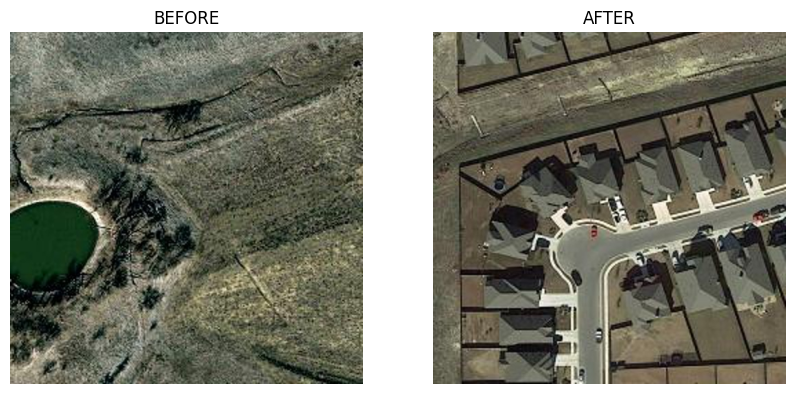

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(before)
plt.title("BEFORE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(after)
plt.title("AFTER")
plt.axis("off")

plt.show()

In [ ]:
def resolution_variation(image):
    low_res = image.resize((256, 256), Image.Resampling.BILINEAR)
    restored = low_res.resize((512, 512), Image.Resampling.BILINEAR)
    return restored

before_resolution = resolution_variation(before)
after_resolution = resolution_variation(after)

print("Original:", before.size)
print("Variation:", before_resolution.size)

Original: (512, 512)
Variation: (512, 512)


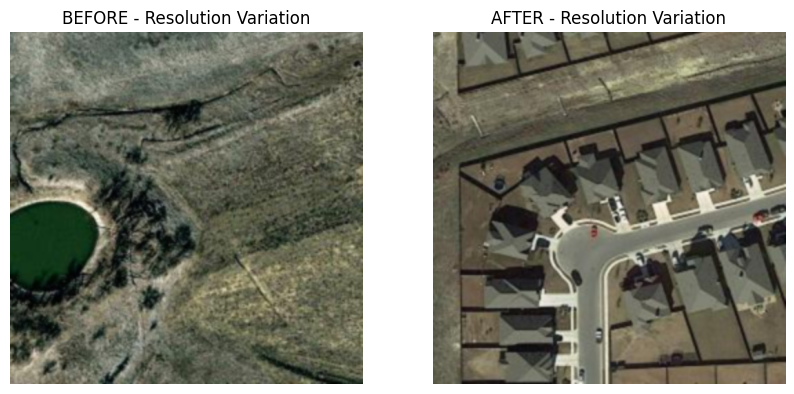

In [ ]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(before_resolution)
plt.title("BEFORE - Resolution Variation")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(after_resolution)
plt.title("AFTER - Resolution Variation")
plt.axis("off")

plt.show()

In [ ]:
def brightness_variation(image, factor=0.7):
    enhancer = ImageEnhance.Brightness(image)
    return enhancer.enhance(factor)

before_brightness = brightness_variation(before)
after_brightness = brightness_variation(after)

print("Original size:", before.size)
print("Brightness variation size:", before_brightness.size)

Original size: (512, 512)
Brightness variation size: (512, 512)


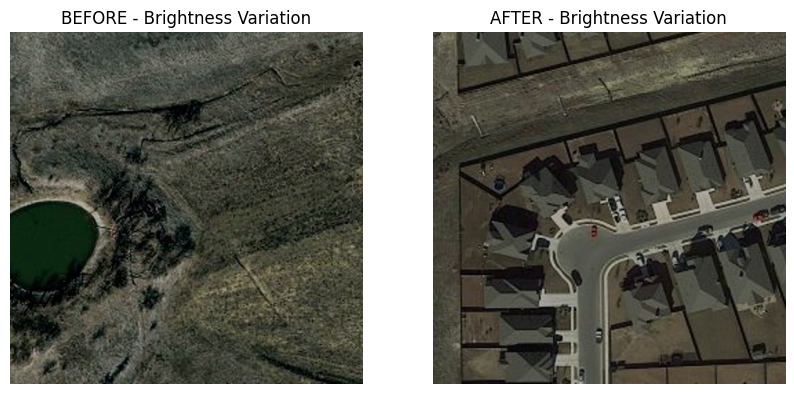

In [ ]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(before_brightness)
plt.title("BEFORE - Brightness Variation")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(after_brightness)
plt.title("AFTER - Brightness Variation")
plt.axis("off")

plt.show()

In [ ]:
from io import BytesIO

def quality_variation(image, quality=50):
    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=quality)
    buffer.seek(0)
    return Image.open(buffer).convert("RGB")

before_quality = quality_variation(before)
after_quality = quality_variation(after)

print("Original size:", before.size)
print("Quality variation size:", before_quality.size)

Original size: (512, 512)
Quality variation size: (512, 512)


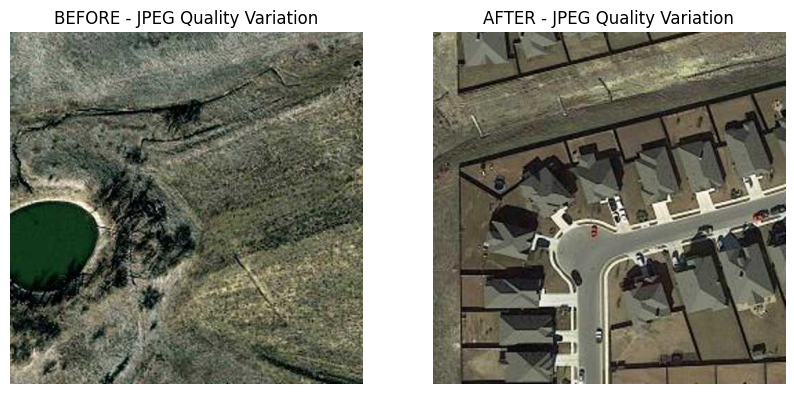

In [ ]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(before_quality)
plt.title("BEFORE - JPEG Quality Variation")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(after_quality)
plt.title("AFTER - JPEG Quality Variation")
plt.axis("off")

plt.show()

In [ ]:
def crop_variation(image, crop_ratio=0.8):
    width, height = image.size

    new_width = int(width * crop_ratio)
    new_height = int(height * crop_ratio)

    left = (width - new_width) // 2
    top = (height - new_height) // 2
    right = left + new_width
    bottom = top + new_height

    cropped = image.crop((left, top, right, bottom))

    return cropped.resize(
        (width, height),
        Image.Resampling.BILINEAR
    )

before_crop = crop_variation(before)
after_crop = crop_variation(after)

print("Original:", before.size)
print("Crop variation:", before_crop.size)

Original: (512, 512)
Crop variation: (512, 512)


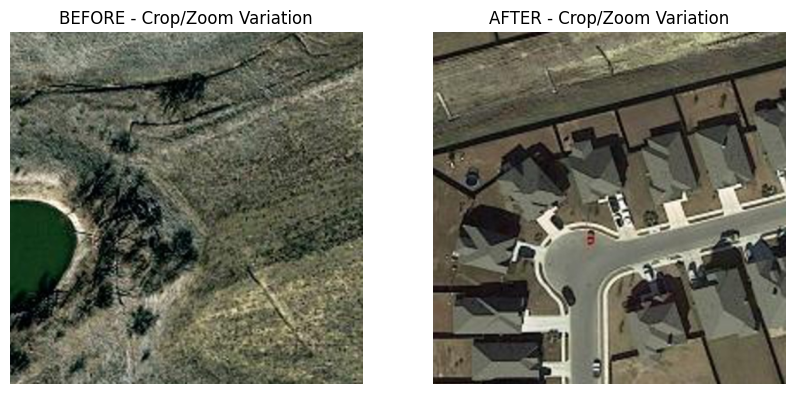

In [ ]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(before_crop)
plt.title("BEFORE - Crop/Zoom Variation")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(after_crop)
plt.title("AFTER - Crop/Zoom Variation")
plt.axis("off")

plt.show()

In [ ]:
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info

model_name = "Qwen/Qwen2.5-VL-3B-Instruct"

processor = AutoProcessor.from_pretrained(model_name)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto"
)

print("Qwen2.5-VL-3B loaded successfully!")

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Qwen2.5-VL-3B loaded successfully!


In [ ]:
import time

def run_task3_inference(before_image, after_image, question):

    prompt = f"""
Compare the BEFORE and AFTER satellite images and answer the question.

Answer only the correct option letter (A, B, C, or D),
or YES or NO if it is a Yes/No question.

Do not explain.
Do not describe the images.

Question:
{question}
"""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": before_image},
            {"type": "image", "image": after_image},
            {"type": "text", "text": prompt}
        ]
    }]

    image_inputs, video_inputs = process_vision_info(messages)

    text_prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = processor(
        text=text_prompt,
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(model.device)

    start_time = time.time()

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=5
        )

    response_time = time.time() - start_time

    generated_ids_trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True
    )

    prediction = output_text[0].strip()

    return prediction, response_time

In [ ]:
question = """
In the eastern portion of the image, along the residential street that was developed,
what change occurred to the sidewalk at that location?

A) The sidewalk was removed to make room for a larger lawn.
B) The sidewalk was newly constructed on previously undeveloped land.
C) The sidewalk was widened to accommodate more foot traffic.
D) The sidewalk was replaced with a gravel path.
"""

ground_truth = "B"

prediction_original, time_original = run_task3_inference(
    before,
    after,
    question
)

print("Condition: Original")
print("Prediction:", prediction_original)
print("Ground Truth:", ground_truth)
print("Correct:", prediction_original.strip().upper().startswith(ground_truth))
print("Response time:", round(time_original, 2), "seconds")

Condition: Original
Prediction: B
Ground Truth: B
Correct: True
Response time: 6.64 seconds


In [ ]:
prediction_resolution, time_resolution = run_task3_inference(
    before_resolution,
    after_resolution,
    question
)

print("Condition: Resolution")
print("Prediction:", prediction_resolution)
print("Ground Truth:", ground_truth)
print(
    "Correct:",
    prediction_resolution.strip().upper().startswith(ground_truth)
)
print("Response time:", round(time_resolution, 2), "seconds")

Condition: Resolution
Prediction: C
Ground Truth: B
Correct: False
Response time: 3.51 seconds


In [ ]:
prediction_brightness, time_brightness = run_task3_inference(
    before_brightness,
    after_brightness,
    question
)

print("Condition: Brightness")
print("Prediction:", prediction_brightness)
print("Ground Truth:", ground_truth)
print(
    "Correct:",
    prediction_brightness.strip().upper().startswith(ground_truth)
)
print("Response time:", round(time_brightness, 2), "seconds")

Condition: Brightness
Prediction: B
Ground Truth: B
Correct: True
Response time: 3.63 seconds


In [ ]:
prediction_quality, time_quality = run_task3_inference(
    before_quality,
    after_quality,
    question
)

print("Condition: JPEG Quality")
print("Prediction:", prediction_quality)
print("Ground Truth:", ground_truth)
print(
    "Correct:",
    prediction_quality.strip().upper().startswith(ground_truth)
)
print("Response time:", round(time_quality, 2), "seconds")

Condition: JPEG Quality
Prediction: B
Ground Truth: B
Correct: True
Response time: 3.55 seconds


In [ ]:
prediction_crop, time_crop = run_task3_inference(
    before_crop,
    after_crop,
    question
)

print("Condition: Crop/Zoom")
print("Prediction:", prediction_crop)
print("Ground Truth:", ground_truth)
print(
    "Correct:",
    prediction_crop.strip().upper().startswith(ground_truth)
)
print("Response time:", round(time_crop, 2), "seconds")

Condition: Crop/Zoom
Prediction: C
Ground Truth: B
Correct: False
Response time: 3.6 seconds


In [ ]:
task3_results = [
    {
        "example": 1,
        "condition": "Original",
        "prediction": prediction_original,
        "ground_truth": ground_truth,
        "correct": prediction_original.strip().upper().startswith(ground_truth),
        "response_time": time_original
    },
    {
        "example": 1,
        "condition": "Resolution",
        "prediction": prediction_resolution,
        "ground_truth": ground_truth,
        "correct": prediction_resolution.strip().upper().startswith(ground_truth),
        "response_time": time_resolution
    },
    {
        "example": 1,
        "condition": "Brightness",
        "prediction": prediction_brightness,
        "ground_truth": ground_truth,
        "correct": prediction_brightness.strip().upper().startswith(ground_truth),
        "response_time": time_brightness
    },
    {
        "example": 1,
        "condition": "JPEG Quality",
        "prediction": prediction_quality,
        "ground_truth": ground_truth,
        "correct": prediction_quality.strip().upper().startswith(ground_truth),
        "response_time": time_quality
    },
    {
        "example": 1,
        "condition": "Crop/Zoom",
        "prediction": prediction_crop,
        "ground_truth": ground_truth,
        "correct": prediction_crop.strip().upper().startswith(ground_truth),
        "response_time": time_crop
    }
]

task3_df = pd.DataFrame(task3_results)

task3_df

,example,condition,prediction,ground_truth,correct,response_time
0,1,Original,B,B,True,6.641062
1,1,Resolution,C,B,False,3.512946
2,1,Brightness,B,B,True,3.625131
3,1,JPEG Quality,B,B,True,3.553543
4,1,Crop/Zoom,C,B,False,3.596090


In [ ]:
sample2 = samples[1]

before2 = sample2["before"]
after2 = sample2["after"]

print("Question / Annotation:")
print(sample2["text"])

print("\nBEFORE image size:", before2.size)
print("AFTER image size:", after2.size)

Question / Annotation:
**Question:** Has the sidewalk at the northeast corner of the intersection been extended eastward along the northern edge of the horizontal road to border the newly developed residential area?\n\n**Answer:** Yes

BEFORE image size: (512, 512)
AFTER image size: (512, 512)


In [ ]:
question2 = """
Has the sidewalk at the northeast corner of the intersection been extended eastward
along the northern edge of the horizontal road to border the newly developed residential area?

Answer only YES or NO.
"""

ground_truth2 = "YES"

print("Ground truth:", ground_truth2)

Ground truth: YES


In [ ]:
before2_resolution = resolution_variation(before2)
after2_resolution = resolution_variation(after2)

before2_brightness = brightness_variation(before2)
after2_brightness = brightness_variation(after2)

before2_quality = quality_variation(before2)
after2_quality = quality_variation(after2)

before2_crop = crop_variation(before2)
after2_crop = crop_variation(after2)

print("All four variations created successfully.")

All four variations created successfully.


In [ ]:
prediction_original2, time_original2 = run_task3_inference(
    before2,
    after2,
    question2
)

print("Prediction:", prediction_original2)
print("Ground Truth:", ground_truth2)
print("Correct:", prediction_original2.strip().upper().startswith(ground_truth2))
print("Response Time:", round(time_original2, 2), "seconds")

Prediction: NO
Ground Truth: YES
Correct: False
Response Time: 3.53 seconds


In [ ]:

conditions2 = [
    ("Original", before2, after2),
    ("Resolution", before2_resolution, after2_resolution),
    ("Brightness", before2_brightness, after2_brightness),
    ("JPEG Quality", before2_quality, after2_quality),
    ("Crop/Zoom", before2_crop, after2_crop)
]

results2 = []

for condition, before_img, after_img in conditions2:

    print(f"\nRunning: {condition}...")

    prediction, response_time = run_task3_inference(
        before_img,
        after_img,
        question2
    )

    prediction_clean = prediction.strip().upper()
    correct = prediction_clean.startswith(ground_truth2)

    results2.append({
        "example": 2,
        "condition": condition,
        "prediction": prediction_clean,
        "ground_truth": ground_truth2,
        "correct": correct,
        "response_time": round(response_time, 2)
    })

    print("Prediction:", prediction_clean)
    print("Ground Truth:", ground_truth2)
    print("Correct:", correct)
    print("Response Time:", round(response_time, 2), "seconds")

# Convert to DataFrame
task3_example2_df = pd.DataFrame(results2)

print("\n" + "="*60)
print("TASK 3 - EXAMPLE 2 RESULTS")
print("="*60)

display(task3_example2_df)


Running: Original...
Prediction: NO
Ground Truth: YES
Correct: False
Response Time: 3.48 seconds

Running: Resolution...
Prediction: NO
Ground Truth: YES
Correct: False
Response Time: 3.5 seconds

Running: Brightness...
Prediction: NO
Ground Truth: YES
Correct: False
Response Time: 3.53 seconds

Running: JPEG Quality...
Prediction: NO
Ground Truth: YES
Correct: False
Response Time: 3.62 seconds

Running: Crop/Zoom...
Prediction: NO
Ground Truth: YES
Correct: False
Response Time: 3.58 seconds

TASK 3 - EXAMPLE 2 RESULTS


,example,condition,prediction,ground_truth,correct,response_time
0,2,Original,NO,YES,False,3.48
1,2,Resolution,NO,YES,False,3.50
2,2,Brightness,NO,YES,False,3.53
3,2,JPEG Quality,NO,YES,False,3.62
4,2,Crop/Zoom,NO,YES,False,3.58


In [ ]:
import re
import pandas as pd
import time

def extract_answer(annotation):
    """
    Extract the ground-truth answer from RSRCC annotation.
    Supports YES/NO and A/B/C/D.
    """
    text = annotation.upper()

    # Look for "Answer: ..."
    match = re.search(r'\*\*ANSWER:\*\*\s*([A-D]|YES|NO)', text)
    if match:
        return match.group(1)

    match = re.search(r'ANSWER:\s*([A-D]|YES|NO)', text)
    if match:
        return match.group(1)

    return None


def extract_question(annotation):
    """
    Extract the question portion from the annotation.
    """
    text = annotation

    match = re.search(
        r'\*\*QUESTION:\*\*\s*(.*?)\s*(?:\*\*ANSWER:\*\*)',
        text,
        flags=re.DOTALL | re.IGNORECASE
    )

    if match:
        return match.group(1).strip()

    match = re.search(
        r'QUESTION:\s*(.*?)\s*ANSWER:',
        text,
        flags=re.DOTALL | re.IGNORECASE
    )

    if match:
        return match.group(1).strip()

    return text


all_results = []

# Keep Example 1 and Example 2 results
all_results.extend(task3_results)
all_results.extend(results2)

# Process Examples 3, 4 and 5
for example_num in range(3, 6):

    sample = samples[example_num - 1]

    before_img = sample["before"]
    after_img = sample["after"]
    annotation = sample["text"]

    question = extract_question(annotation)
    ground_truth = extract_answer(annotation)

    print("\n" + "="*70)
    print(f"EXAMPLE {example_num}")
    print("="*70)
    print("Question:", question)
    print("Ground Truth:", ground_truth)

    if ground_truth is None:
        print("Could not extract ground truth. Skipping.")
        continue

    # Create variations
    variations = [
        ("Original", before_img, after_img),
        ("Resolution",
         resolution_variation(before_img),
         resolution_variation(after_img)),
        ("Brightness",
         brightness_variation(before_img),
         brightness_variation(after_img)),
        ("JPEG Quality",
         quality_variation(before_img),
         quality_variation(after_img)),
        ("Crop/Zoom",
         crop_variation(before_img),
         crop_variation(after_img))
    ]

    for condition, before_var, after_var in variations:

        print(f"\nRunning {condition}...")

        prediction, response_time = run_task3_inference(
            before_var,
            after_var,
            question
        )

        prediction_clean = prediction.strip().upper()

        correct = prediction_clean.startswith(ground_truth)

        print("Prediction:", prediction_clean)
        print("Correct:", correct)

        all_results.append({
            "example": example_num,
            "condition": condition,
            "prediction": prediction_clean,
            "ground_truth": ground_truth,
            "correct": correct,
            "response_time": round(response_time, 2)
        })


# Final combined dataframe
task3_all_results = pd.DataFrame(all_results)

print("\n" + "="*70)
print("TASK 3 - ALL RESULTS")
print("="*70)

display(task3_all_results)

# Save locally
task3_all_results.to_csv(
    "task3_all_results.csv",
    index=False
)

print("\nSaved as: task3_all_results.csv")


EXAMPLE 3
Question: Between the two images, what change occurred to the land located at the top center, north of the circular cul-de-sac?\n\n**A)** An existing structure was demolished.\n**B)** A new residential building was constructed.\n**C)** The area was cleared to create a public park.\n**D)** A large parking lot was paved over the dirt.\n\n
Ground Truth: B

Running Original...
Prediction: B
Correct: True

Running Resolution...
Prediction: B
Correct: True

Running Brightness...
Prediction: A
Correct: False

Running JPEG Quality...
Prediction: B
Correct: True

Running Crop/Zoom...
Prediction: A
Correct: False

EXAMPLE 4
Question: Is there any detectable anomaly or global alteration in the scene composition between these two images?\n
Ground Truth: NO

Running Original...
Prediction: D
Correct: False

Running Resolution...
Prediction: D
Correct: False

Running Brightness...
Prediction: D
Correct: False

Running JPEG Quality...
Prediction: B
Correct: False

Running Crop/Zoom...
Pred

,example,condition,prediction,ground_truth,correct,response_time
0,1,Original,B,B,True,6.641062
1,1,Resolution,C,B,False,3.512946
2,1,Brightness,B,B,True,3.625131
3,1,JPEG Quality,B,B,True,3.553543
4,1,Crop/Zoom,C,B,False,3.596090
5,2,Original,NO,YES,False,3.480000
6,2,Resolution,NO,YES,False,3.500000
7,2,Brightness,NO,YES,False,3.530000
8,2,JPEG Quality,NO,YES,False,3.620000
9,2,Crop/Zoom,NO,YES,False,3.580000



Saved as: task3_all_results.csv


In [ ]:
from datasets import load_dataset
import random
import pandas as pd

random.seed(42)

dataset = load_dataset(
    "google/RSRCC",
    split="test",
    streaming=True
)

task3_samples = []

for example in dataset:
    task3_samples.append(example)

    if len(task3_samples) == 100:
        break

samples_100 = task3_samples

print("Total samples collected:", len(samples_100))

task3_meta = pd.DataFrame([
    {
        "index": i,
        "annotation": sample["text"]
    }
    for i, sample in enumerate(samples_100)
])

print("100-sample set:", len(samples_100))
print("\nFirst 5 annotations:")
display(task3_meta.head())

Resolving data files:   0%|          | 0/12835 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/2521 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3653 [00:00<?, ?it/s]

Total samples collected: 100
100-sample set: 100

First 5 annotations:


,index,annotation
0,0,**Question:** In the eastern portion of the im...
1,1,**Question:** Has the sidewalk at the northeas...
2,2,"**Question:** Between the two images, what cha..."
3,3,**Question:** Is there any detectable anomaly ...
4,4,**Question:** What change can be observed rega...


In [ ]:
import os
import zipfile
import pandas as pd
from google.colab import files

base_dir = "task3_samples"

conditions = [
    "Original",
    "Resolution",
    "Brightness",
    "JPEG_Quality",
    "Crop_Zoom"
]

for condition in conditions:
    os.makedirs(
        os.path.join(base_dir, condition),
        exist_ok=True
    )

metadata = []

for sample_number, sample in enumerate(samples_100, start=1):

    before = sample["before"]
    after = sample["after"]
    annotation = sample["text"]

    question = extract_question(annotation)
    ground_truth = extract_answer(annotation)

    variations = {
        "Original": (before, after),
        "Resolution": (
            resolution_variation(before),
            resolution_variation(after)
        ),
        "Brightness": (
            brightness_variation(before),
            brightness_variation(after)
        ),
        "JPEG_Quality": (
            quality_variation(before),
            quality_variation(after)
        ),
        "Crop_Zoom": (
            crop_variation(before),
            crop_variation(after)
        )
    }

    for condition, (before_img, after_img) in variations.items():

        before_filename = f"sample_{sample_number:03d}_before.jpg"
        after_filename = f"sample_{sample_number:03d}_after.jpg"

        before_path = os.path.join(
            base_dir,
            condition,
            before_filename
        )

        after_path = os.path.join(
            base_dir,
            condition,
            after_filename
        )

        before_img.convert("RGB").save(
            before_path,
            "JPEG",
            quality=95
        )

        after_img.convert("RGB").save(
            after_path,
            "JPEG",
            quality=95
        )

        metadata.append({
            "sample": sample_number,
            "condition": condition,
            "question": question,
            "ground_truth": ground_truth,
            "before_image": f"{condition}/{before_filename}",
            "after_image": f"{condition}/{after_filename}"
        })

metadata_df = pd.DataFrame(metadata)

metadata_df.to_csv(
    os.path.join(
        base_dir,
        "Task3_100_Sample_Metadata.csv"
    ),
    index=False
)

zip_filename = "Task3_100_Sample_Dataset.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, filenames in os.walk(base_dir):
        for filename in filenames:
            filepath = os.path.join(root, filename)

            zipf.write(
                filepath,
                os.path.relpath(filepath, base_dir)
            )

print("Samples:", len(samples_100))
print("Conditions:", len(conditions))
print("Total image pairs:", len(metadata_df))
print("Total individual images:", len(metadata_df) * 2)
print("ZIP file:", zip_filename)

display(metadata_df.head())

files.download(zip_filename)

Samples: 100
Conditions: 5
Total image pairs: 500
Total individual images: 1000
ZIP file: Task3_100_Sample_Dataset.zip


,sample,condition,question,ground_truth,before_image,after_image
0,1,Original,"In the eastern portion of the image, along the...",B,Original/sample_001_before.jpg,Original/sample_001_after.jpg
1,1,Resolution,"In the eastern portion of the image, along the...",B,Resolution/sample_001_before.jpg,Resolution/sample_001_after.jpg
2,1,Brightness,"In the eastern portion of the image, along the...",B,Brightness/sample_001_before.jpg,Brightness/sample_001_after.jpg
3,1,JPEG_Quality,"In the eastern portion of the image, along the...",B,JPEG_Quality/sample_001_before.jpg,JPEG_Quality/sample_001_after.jpg
4,1,Crop_Zoom,"In the eastern portion of the image, along the...",B,Crop_Zoom/sample_001_before.jpg,Crop_Zoom/sample_001_after.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def run_qwen(model, processor, before_image, after_image, question):

    prompt = f"""
You are analyzing two satellite images of the same location.
The first image is BEFORE.
The second image is AFTER.

Compare the two images and answer the question based only on the changes.

If the question is Yes/No, answer only YES or NO.
If the question is multiple choice, answer only A, B, C, or D.
If the question is not Yes/NO or multiple choice then only explain the answer.

Do not describe the images.

Question:
{question}
"""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": before_image},
            {"type": "image", "image": after_image},
            {"type": "text", "text": prompt}
        ]
    }]

    image_inputs, video_inputs = process_vision_info(messages)

    text_prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = processor(
        text=text_prompt,
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(model.device)

    start_time = time.time()

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=5
        )

    response_time = time.time() - start_time

    generated_ids_trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True
    )

    prediction = output_text[0].strip()

    return prediction, response_time

In [ ]:
import re

def normalize_prediction(prediction, ground_truth):
    prediction = str(prediction).strip().upper()
    ground_truth = str(ground_truth).strip().upper()

    if ground_truth in ["YES", "NO"]:
        match = re.match(r"^\s*(YES|NO)\b", prediction)

        if match:
            return match.group(1)

        match = re.search(
            r"\b(?:ANSWER|CHOICE)\s*[:\-]?\s*(YES|NO)\b",
            prediction
        )

        return match.group(1) if match else prediction

    match = re.match(
        r"^\s*\(?([ABCD])\)?(?:\s*[\).,:-]|\s*$)",
        prediction
    )

    if match:
        return match.group(1)

    match = re.search(
        r"\b(?:ANSWER|OPTION|CHOICE)\s*[:\-]?\s*\(?([ABCD])\)?\b",
        prediction
    )

    return match.group(1) if match else prediction

In [ ]:
from tqdm.auto import tqdm
import pandas as pd
import re

results_100_v2 = []

for sample_number, sample in enumerate(
    tqdm(samples_100, desc="Running 100 samples"),
    start=1
):

    before = sample["before"]
    after = sample["after"]
    annotation = sample["text"]

    question = extract_question(annotation)
    ground_truth = extract_answer(annotation)

    if ground_truth is None:
        continue

    variations = [
        ("Original", before, after),
        (
            "Resolution",
            resolution_variation(before),
            resolution_variation(after)
        ),
        (
            "Brightness",
            brightness_variation(before),
            brightness_variation(after)
        ),
        (
            "JPEG Quality",
            quality_variation(before),
            quality_variation(after)
        ),
        (
            "Crop/Zoom",
            crop_variation(before),
            crop_variation(after)
        )
    ]

    for condition, before_img, after_img in variations:

        try:
            prediction, response_time = run_qwen(
                model,
                processor,
                before_img,
                after_img,
                question
            )

            prediction_clean = str(prediction).strip().upper()

            normalized_prediction = normalize_prediction(
                prediction_clean,
                ground_truth
            )

            correct = normalized_prediction == ground_truth

            results_100_v2.append({
                "sample": sample_number,
                "condition": condition,
                "question": question,
                "prediction": prediction_clean,
                "normalized_prediction": normalized_prediction,
                "ground_truth": ground_truth,
                "correct": correct,
                "response_time_seconds": round(response_time, 2)
            })

        except Exception as e:

            print(
                f"Error in sample {sample_number}, "
                f"condition {condition}: {e}"
            )

            results_100_v2.append({
                "sample": sample_number,
                "condition": condition,
                "question": question,
                "prediction": "ERROR",
                "normalized_prediction": "ERROR",
                "ground_truth": ground_truth,
                "correct": False,
                "response_time_seconds": None
            })

task3_100_v2_df = pd.DataFrame(results_100_v2)

task3_100_v2_df.to_csv(
    "task3_100_results_v2.csv",
    index=False
)

print("\nTotal evaluations:", len(task3_100_v2_df))
print("Correct predictions:", task3_100_v2_df["correct"].sum())

print(
    "Overall accuracy:",
    round(task3_100_v2_df["correct"].mean() * 100, 2),
    "%"
)

display(task3_100_v2_df.head(20))

Running 100 samples:   0%|          | 0/100 [00:00<?, ?it/s]


Total evaluations: 500
Correct predictions: 330
Overall accuracy: 66.0 %


,sample,condition,question,prediction,normalized_prediction,ground_truth,correct,response_time_seconds
0,1,Original,"In the eastern portion of the image, along the...",C) THE SIDEWALK WAS,C,B,False,6.40
1,1,Resolution,"In the eastern portion of the image, along the...",C) THE SIDEWALK WAS,C,B,False,4.37
2,1,Brightness,"In the eastern portion of the image, along the...",C) THE SIDEWALK WAS,C,B,False,4.33
3,1,JPEG Quality,"In the eastern portion of the image, along the...",C) THE SIDEWALK WAS,C,B,False,4.41
4,1,Crop/Zoom,"In the eastern portion of the image, along the...",C) THE SIDEWALK WAS,C,B,False,4.50
5,2,Original,Has the sidewalk at the northeast corner of th...,YES,YES,YES,True,4.38
6,2,Resolution,Has the sidewalk at the northeast corner of th...,YES,YES,YES,True,4.34
7,2,Brightness,Has the sidewalk at the northeast corner of th...,YES,YES,YES,True,4.29
8,2,JPEG Quality,Has the sidewalk at the northeast corner of th...,YES,YES,YES,True,4.56
9,2,Crop/Zoom,Has the sidewalk at the northeast corner of th...,YES,YES,YES,True,4.13


In [ ]:
print("Total evaluations:", len(task3_100_v2_df))
print("Correct:", task3_100_v2_df["correct"].sum())
print(
    "Accuracy:",
    round(
        task3_100_v2_df["correct"].mean() * 100,
        2
    ),
    "%"
)

Total evaluations: 500
Correct: 330
Accuracy: 66.0 %


In [ ]:
condition_accuracy = (
    task3_100_v2_df
    .groupby("condition")["correct"]
    .agg(
        total="count",
        correct="sum",
        accuracy="mean"
    )
)

condition_accuracy["accuracy"] *= 100

print(condition_accuracy)

              total  correct  accuracy
condition                             
Brightness      100       65      65.0
Crop/Zoom       100       63      63.0
JPEG Quality    100       67      67.0
Original        100       69      69.0
Resolution      100       66      66.0


In [ ]:
time_analysis = (
    task3_100_v2_df
    .groupby("condition")["response_time_seconds"]
    .agg(
        average_time="mean",
        min_time="min",
        max_time="max"
    )
)

print(time_analysis.round(2))

              average_time  min_time  max_time
condition                                     
Brightness            4.12      3.92      4.36
Crop/Zoom             4.13      3.92      4.50
JPEG Quality          4.12      3.90      4.56
Original              4.15      3.89      6.40
Resolution            4.13      3.87      4.42


In [ ]:
print(samples_100[0].keys())

dict_keys(['before', 'after', 'text'])
